# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [ ]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [ ]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.17


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [ ]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [ ]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [ ]:
QUESTION = "Яка столиця Франції?"

In [ ]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [ ]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [ ]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.0 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 4.7 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [ ]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 1.8 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 5.5 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [ ]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [ ]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [ ]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [ ]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [ ]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,17.34,2.67,2.40,55.22,23.71
int8,4.42,5.01,5.73,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.83,2.81,2.76,55.34,29.79
int2,1.81,2.39,2.89,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

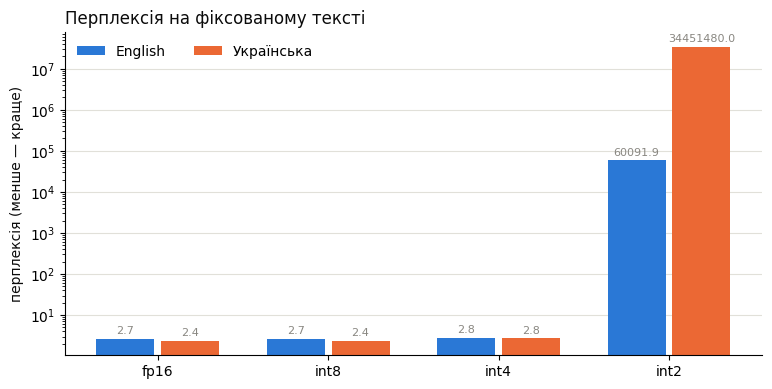

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [ ]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [ ]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [ ]:
VOTES = {1: "B", 2: "A", 3: "B", 4: "B", 5: "="}

In [ ]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,int4
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,fp16
2,Explain in three sentences why the sky is blue.,fp16,int4,int4
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,fp16
4,Write a Python function that checks whether a ...,int4,fp16,однаково


fp16 краща: 2, int4 краща: 2, однаково: 1


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [ ]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

---

# Лабораторна 4. Локальний запуск і оптимізація моделей

**Ідея для застосунку:**

Генератор акордових прогресій з автоперевіркою. Модель повертає JSON з акордами, а код сам перевіряє результат: чи всі акорди діатонічні до тональності, чи рівно 8 тактів, чи валідний JSON.

## 0.1 Відповіді на питання

### 1. У розділі 1.5 демо модель помиляється, рахуючи літеру «р» у слові «трансформер», — причому і без міркувань, і з ними. Поясніть, чому. Підтвердіть пояснення кодом.

Модель токенезує слова, тобто зберігає символи комбінаціями і коли просимо підрахувати клькість входжень літер вона просто відгадує результат. Без міркування модель просто відповіла 1. З міркуваннями стає не краще: у thinking-режимі модель розписала слово як «т-р-а-н-с-т-о-м-е-р» і отримала 2 замість 3.

In [ ]:
word = "трансформер"
tokens = tokenizer.encode(word, add_special_tokens=False)

print("Кількість входжень літери «р»:", word.count("р"))
print("Позиції в слові:", [i for i, c in enumerate(word, 1) if c == "р"])
print("Кількість токенів:", len(tokens))
print("ID токенів:", tokens)

Кількість входжень літери «р»: 3
Позиції в слові: [2, 8, 11]
Кількість токенів: 5
ID токенів: [1792, 34582, 2247, 56619, 7599]


### 2. Як у розділі 2.4 демо змінюються перплексія й метрики перекладу від fp16 до int2? Між якими варіантами стрибок найбільший?

Перплексія:
  - EN: 2.67 → 2.67 → 2.81 → 60 092.
  - UK: 2.40 → 2.40 → 2.76 → 3.4·10⁷.
  - chrF: 55.2 → 58.3 → 55.3 → 0.19.
  - BLEU: 23.7 → 26.2 → 29.8 → 0.12.

Найбільший стрибок між int4 і int2, де модель повністю ламається. fp16 → int8 → int4 різниця невелика.

### 3. Чи однаково зростає перплексія для англійської й української? Порівняйте з висновком зі слайду «Де може просідати якість при квантизації».

Ні. На int4 EN зросла на ~5% (2.67→2.81), UK на ~15% (2.40→2.76). На int2 обидві мови зламані, але в UK значно сильніше. Це узгоджується з тезою слайду лекції про те, що мови з нелатинською абеткою страждають від квантизації більше.

### 4. Чи збігається ваш вибір у сліпому порівнянні (розділ 2.5 демо) з тим, що показали автоматичні метрики? Чи помітили ви різницю там, де метрики майже не змінилися, — або навпаки?

Загалом збігається. У моїх голосах явного переможця немає. Метрики теж майже однакові для fp16 та int4. Різниця помітна в українських текстах: запити 1, 2 і 4 в int4 мають кривіші формулювання і коротший лист. Це видно в перплексії UK +15%, але метрики перекладу цього не показали. В англійській відповіді й коді різниці практично нема.

### 5. Знайдіть у таблиці перекладів (розділ 2.4 демо) правильний переклад, який відрізняється від еталона словами. Як на нього реагують BLEU і chrF?

Приклад: fp16 переклав «Please send me the report by the end of the day» як «Надішліть мені звіт до кінця дня». Це правильно, але без «Будь ласка» з еталона. Подібний випадок: «повинні подати» замість «мають здати». chrF реагує м'яко, бо більшість символів збігається. BLEU штрафує сильніше, бо слова та n-грами не збігаються, а до того ж діє штраф за коротшу відповідь. Через це на 10 реченнях BLEU шумить: у int4 він вищий, ніж у fp16, хоча якість не краща.

### 6. У скільки разів зменшилася памʼять у таблиці розділу 2.4 демо і чому не рівно вдвічі, вчетверо й увосьмеро? Чи стала генерація швидшою?

Памʼять зменшувалась поступово: 8.04 → 4.42 → 2.73 → 1.81 GB, тобто у 1.8×, 2.9× і 4.4×. Не 2×/4×/8×, бо квантизуються лише nn.Linear. Ембединги, нормалізації й вихідний шар лишаються в fp16, а ще додаються масштаби блоків. Генерація не пришвидшилась, а сповільнилась: 16.7 → 5.9 → 2.9 → 3.0 tokens/s. T4 множить лише у 16 бітах, тож ваги щоразу розпаковуються, а розпаковка на чистому PyTorch.

### 7. Чому Base-модель у розділі 1.2 відповідає на питання новими питаннями? Сформулюйте промпт так, щоб Base-модель усе ж дала відповідь. Наведіть код і результат.

Base-модель навчена лише продовжувати текст. Рішенням стає few-shot у форматі «питання → відповідь»:

In [ ]:
prompt = (
          "Питання: Столиця Німеччини?\nВідповідь: Берлін\n"
          "Питання: Столиця України?\nВідповідь: Київ\n"
          "Питання: Столиця Італії?\nВідповідь: Рим\n"
          "Питання: Столиця Франції?\nВідповідь:"
        )
print(generate_raw(BASE_MODEL, prompt, 4))

 Париж



### 8. Скільки токенів і часу забрали міркування в розділі 1.4 порівняно з відповіддю без міркувань? Чому модель міркує англійською, хоча питання українською?

Без міркувань 252 токени і 2.1 с, з міркуваннями 569 токенів і 4.8 с, тобто у ~2.3× більше. Модель міркує англійською, бо ланцюжки міркувань у її навчальних даних і RL переважно англійські, а це її найсильніша мова.

### 9. Знайдіть задачу, на якій режим міркування дає правильну відповідь, а без нього модель помиляється. Наведіть промпт і обидві відповіді.

In [ ]:
compare_thinking(
    "Потяг виїхав о 9:40 і їхав 3 год 35 хв, потім стояв на пересадці 50 хв "
    "А далі їхав ще 2 год 45 хв. О котрій він прибув?"
)

=== think=False | токенів: 370 | генерація: 3.5 с
--- відповідь:
Давайте розрахуємо, о котрій відплив після потягу.

1. **Потяг виїхав о 9:40**.
2. **Їхав 3 год 35 хв** — це:
   - 3 год = 180 хв
   - 35 хв = 35 хв
   - Всього: 180 + 35 = **215 хв**

   Отже, потяг прибув на пересадку о:
   - 9:40 + 215 хв = **12:15**

3. **Стояв на пересадці 50 хв** — це:
   - 50 хв = 50 хв

   Отже, потяг прибув на місце прибування о:
   - 12:15 + 50 хв = **12:55**

4. **Їхав ще 2 год 45 хв** — це:
   - 2 год = 120 хв
   - 45 хв = 45 хв
   - Всього: 120 + 45 = **165 хв**

   Отже, потяг прибув о:
   - 12:55 + 165 хв = **14:50**

**Відповідь:** Потяг прибув **о 14:50**.

=== think=True | токенів: 1666 | генерація: 17.2 с
--- міркування (3569 символів), початок:
Okay, let's see. The problem is about figuring out when the train arrives, given its departure time and the time it spends traveling and waiting. So, the train leaves at 9:40, travels for 3 hours and 35 minutes, then stays at the station for 50 

### 10. У функціях generate_raw і chat (розділ 1.1) стоять temperature: 0 і seed: 1. Навіщо?

temperature: 0 дає декодування без випадковості. seed фіксує решту випадковості. Разом це робить відповіді відтворюваними, і режими think=False і think=True можна порівнювати.

### 11. Чому в секції 2 використовуємо fp16, а не bf16? Що показує torch.cuda.get_device_capability() на T4 і як це з цим повʼязано?

T4 має compute capability (7, 5), а апаратна підтримка bf16 починається з 8.0 (Ampere, A100). У коді саме це перевіряє `get_device_capability()[0] < 8`. Тому беремо fp16: він підтримується на T4, а для інференсу готової моделі різниця з bf16 мала.

### 12. Скільки параметрів у моделі з розділу 2.1 і скільки памʼяті має займати її fp16-версія за формулою з лекції? Порівняйте з «памʼяттю моделі» в таблиці розділу 2.4.

У секції 2 використовується Qwen3-4B, це модель приблизно на 4 мільярди параметрів. Вага fp16 = параметри × 2 байти. За формулою 4.0·10⁹ × 2 ≈ 8 GB, з запасом у 20% виходить приблизно 9,6 GB, але таблиця дає саме 8.04 GB.

### 13. Що таке перплексія (розділ 2.2) і чому її не можна порівнювати між англійською й українською? Порахуйте перплексію fp16-моделі на випадковому наборі слів замість осмисленого тексту й поясніть результат.

Перплексія = exp(середня крос-ентропія на токен), тобто з скількох варіантів модель у середньому вагається. Між мовами її не порівняти, бо токенізація різна: українські слова ріжуться на більше токенів, і багато з них легко передбачити. Тому UK 2.4 виходить нижче за EN 2.67, хоча українську модель знає гірше. Для випадкових слів:

In [ ]:
import random

gc.collect(); torch.cuda.empty_cache()
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE)

words = PPL_TEXT["English"].replace(",", "").replace(".", "").replace(":", "").split()
random.seed(0)
shuffled = words.copy()
random.shuffle(shuffled)

pool = sorted(t[1:] for t in tokenizer.get_vocab()
              if t.startswith("Ġ") and t[1:].isascii() and t[1:].isalpha() and len(t) > 4)
random.seed(0)
rand_words = random.sample(pool, len(words))

texts = {
    "Осмислений текст": PPL_TEXT["English"],
    "Ті самі слова вперемішку": " ".join(shuffled),
    "Випадкові слова зі словника": " ".join(rand_words),
}
for name, text in texts.items():
    print(f"{name}: {perplexity(model, text):.1f}")

del model
gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Осмислений текст: 2.7
Ті самі слова вперемішку: 395.0
Випадкові слова зі словника: 233769.5


### 14. Чому «пік VRAM» у таблиці розділу 2.4 більший за «памʼять моделі»? Що ще, крім ваг, займає памʼять під час генерації?

Крім ваг, памʼять займають KV-кеш, активації, логіти - словник ~152k токенів, тимчасові буфери, у квантизованих варіантах ще й розпаковані в fp16 шари, та службова памʼять CUDA. Різниця майже стала для всіх варіантів, ≈0.6 GB.

### 15. Скільки разів у сліпому порівнянні (розділ 2.5) ви обрали fp16, int4 чи «однаково»? Наскільки впевнено можна робити висновки з 5 порівнянь і скільки їх знадобилося б для надійного висновку?

За моїми голосами: fp16 — 2, int4 — 2, «однаково» — 1, тобто це практично монетка. П'ять порівнянь нічого не доводять. Для різниці у вподобаннях 60/40 потрібно близько 200 порівнянь, для 70/30 — близько 50, причому на різноманітних запитах і від кількох оцінювачів.

### 16. Як саме «ламається» модель у int2 (розділ 2.6)? Опишіть типові помилки у відповідях. Чи помітні їхні ознаки вже в int4?

int2 видає шум: повтори на кшталт \ \ \, h h h, again, ever, taken, рядки нулів, суміш скриптів, � і відсутність зупинки аж до ліміту токенів. chrF там 0.19. В int4 ознаки вже є, але тонкі. Це лексичні й фактичні помилки в українській: «Бібліотека відкрита тільки з 1 по 7», «зареєструвати стіл», «вільний Wi-Fi». Також менше деталей і дивні формулювання. Частину помилок: «Новий модель», «засіб» замість «парасольку» має й fp16, тож вони не лише від квантизації.

17. Повторіть секцію 2 з меншою моделлю (наприклад, Qwen/Qwen3-1.7B). Чи сильніше квантизація бʼє по меншій моделі? Порівняйте перплексію й chrF з результатами для 4B.

Менша модель гірша вже в fp16 і значно сильніше страждає від квантизації.

| Модель | Варіант | Перплексія (EN) | chrF |
|---|---|---|---|
| Qwen3-4B | fp16 | 2.67 | 55.22 |
| Qwen3-4B | int4 | 2.81 | 55.34 |
| Qwen3-1.7B | fp16 | 4.35 | 48.74 |
| Qwen3-1.7B | int4 | 7.52 | 29.01 |

- **4B** на int4 майже не втрачає якість: перплексія 2.67 → 2.81, chrF без змін.
- **1.7B** на int4 помітно деградує: перплексія 4.35 → 7.52, chrF 48.74 → 29.01.
- **int2** ламає обидві моделі: перплексія різко зростає, chrF майже 0.

Отже, квантизація до int4 б'є по меншій моделі значно сильніше, а int2 непридатний для обох.

### 18. Поясніть принцип параметру OLLAMA_NUM_PARALLEL в ollama з демо?

Параметр задає, скільки запитів Ollama обробляє паралельно для однієї завантаженої моделі. Запити батчаться в одних обчисленнях, тому пропускна здатність росте. Платимо памʼяттю: під кожен паралельний слот виділяється свій KV-кеш. Окрема відповідь від цього не обов’язково стане швидшою.

### 19. Чому майже всі сучасні моделі зберігаються в bf16?

bf16 має такий самий діапазон, як fp32, але вдвічі менший розмір. Навчання в ньому стабільне без масштабування втрат, тоді як fp16 легко переповнюється. Моделі тренують у bf16 на сучасних GPU/TPU, тож ваги й зберігають як є. Перехід fp32 ↔ bf16 тривіальний, а памʼяті потрібно вдвічі менше.

### 20. Для чого всі рантайми моделей слідують протоколу OpenAI? Як це повʼязано з ChatGPT?

Протокол OpenAI не те саме, що компанія OpenAI. Це відкритий HTTP-клієнт (ліцензія Apache 2.0) для цього формату запитів. Запити йдуть лише на адресу з base_url. Рантайми Ollama, vLLM, llama.cpp, LM Studio його реалізують, тож локальну модель можна підставити в готовий застосунок, змінивши лише base_url, без прив'язки до вендора.

## 1. Локальна модель і власний застосунок

### 1.1. Залізо

Спочатку я перевірив характеристики свого ноутбука.

| Характеристика | Значення | Звідки отримав |
|---|---|---|
| Процесор | Intel Core i5-8350U, 1,70 ГГц, 4 ядра / 8 потоків | `Win32_Processor` |
| RAM | 16 ГБ DDR4, 2400 MT/s | `Win32_PhysicalMemory` |
| Відеокарта | Intel UHD Graphics 620 |`Win32_VideoController` |
| VRAM | інтегрована графіка використовує загальну RAM | `Win32_VideoController`|
| Пропускна здатність RAM | 38,4 GB/s два канали, 2400 MT/s | Розрахунок за характеристиками пам'яті |

Теоретичну пропускну здатність оперативної пам'яті розрахував за швидкістю передачі даних 2400 MT/s, шириною каналу 8 байтів та двома каналами:

$$
B_{\mathrm{RAM}}=2400\cdot10^6\cdot8\cdot2=38{,}4\ \mathrm{GB/s}.
$$

Два модулі по 8 ГБ вказують на двоканальний режим. Це значення близьке до специфікації процесора на Intel ARK (37,5 GiB/s).

Головне обмеження мого ноутбука — відсутність дискретної відеокарти. Ваги моделі читатимуться з оперативної пам'яті, тому швидкість генерації обмежена пропускною здатністю RAM, а не VRAM. Крім того, 16 ГБ RAM ділять між собою Windows, браузер та інші програми, тому для моделі й KV-кешу реально доступна лише частина цього обсягу. Через це для локального запуску розглядатиму невеликі моделі з квантизованими вагами.

### 1.2. Розрахунок

#### Бюджет пам'яті

Перед вимірюванням перевірив вільну RAM за допомогою `Win32_OperatingSystem`, `FreePhysicalMemory`: **7,24 ГБ** з відкритим браузером і **12,95 ГБ** без нього. Для запасу беру бюджет **7 ГБ**: застосунок працюватиме разом із браузером.

#### Пам'ять для ваг

За формулою з лекції:

$$
M_W=P\cdot\frac{Q}{8}\cdot(1+O),
$$

де $P$ — кількість параметрів у мільярдах, $Q$ — біти на параметр, $O=0{,}2$ — запас на рантайм (10–30% за лекцією). Для Qwen3-1.7B за ідеальними 4 бітами:

$$
M_W=1{,}7\cdot\frac{4}{8}\cdot1{,}2\approx1{,}02\ \mathrm{GB}.
$$

Формат Q4_K_M зберігає частину тензорів у вищій точності, тому реальні файли більші за ідеальні 4 біти. Фактичні розміри для моделей Qwen3-4B та Qwen3-1.7B взяв з `ollama list`, розміри для Qwen3-0.6B і Qwen3-8B взяті з каталогу ollama.com/library/qwen3 - ці моделі не завантажував:

| Модель | Файл Q4_K_M, GB | Ідеальні 4 біти ×1,2, GB |
|---|---:|---:|
| Qwen3-0.6B | 0,52 | 0,36 |
| Qwen3-1.7B | 1,4 | 1,02 |
| Qwen3-4B | 2,5 | 2,40 |
| Qwen3-8B | 5,2 | 4,80 |

#### KV-кеш для контексту 4096

$$
M_{KV}=2\cdot L\cdot H_{KV}\cdot d_{\mathrm{head}}\cdot b\cdot C,
$$

де $L$ — кількість шарів, $H_{KV}$ — KV-голови, $d_{\mathrm{head}}$ — розмір голови, $b=2$ (FP16), $C=4096$. Параметри беру з `config.json` моделей на Hugging Face.

Для Qwen3-4B ($L=36$, $H_{KV}=8$, $d_{\mathrm{head}}=128$):

$$
M_{KV}=2\cdot36\cdot8\cdot128\cdot2\cdot4096=603\,979\,776\ \mathrm{B}=576\ \mathrm{MiB}.
$$

| Модель | Шарів | KV-голів | KiB/токен | KV при 4096, MiB |
|---|---:|---:|---:|---:|
| Qwen3-0.6B | 28 | 8 | 112 | 448 |
| Qwen3-1.7B | 28 | 8 | 112 | 448 |
| Qwen3-4B | 36 | 8 | 144 | 576 |
| Qwen3-8B | 36 | 8 | 144 | 576 |

#### Чи вміститься і яка стеля швидкості

Повна оцінка: файл ваг із запасом 20% плюс KV-кеш. Стеля швидкості за формулою з лекції:

$$
v_{\max}\approx\frac{B_{\mathrm{RAM}}}{M_W}=\frac{38{,}4}{M_W},
$$

реальні рантайми дають 60–90% від стелі.

| Модель | Пам'ять разом, GB | Влазить у 7 ГБ? | Стеля, tok/s | Очікувано (60–90%), tok/s |
|---|---:|:-:|---:|---:|
| Qwen3-0.6B | 1,10 | так | 73,8 | 44–66 |
| Qwen3-1.7B | 2,15 | так | 27,4 | 16–25 |
| Qwen3-4B | 3,60 | так | 15,4 | 9–14 |
| Qwen3-8B | 6,84 | на межі | 7,4 | 4–7 |

Qwen3-8B теоретично вміщується в 12,95 ГБ вільної RAM, але з браузером (7,24 ГБ) запасу майже немає, а швидкість 4–7 tok/s надто низька для інтерактивного застосунку. Тому її не розглядаю. Розрахунок стосується лише генерації; обробка промпту на CPU впирається в обчислення, тому TTFT буде помітним.

### 1.3. Вибір моделі й рантайму

**Рантайм.** Обрав **Ollama**: працює у Windows, одна команда завантажує модель, сама визначає розподіл між CPU і GPU і віддає OpenAI-сумісний API на `http://localhost:11434/v1`. Контроль над кожним параметром, який дає llama.cpp, мені не потрібен, а vLLM розрахований на GPU NVIDIA і багато користувачів.

**Тип моделі.** Потрібна **Instruct**-модель: застосунок виконує чітку інструкцію й має повернути структурований JSON, а Base-модель лише продовжувала б текст. Режим міркування **вимикаю**: відповідь має бути короткою, а міркування збільшили б затримку в кілька разів без користі для такої задачі. Правильність акордів перевірятиме код застосунку.

**Формат і квантизація.** GGUF, квантизація Q4_K_M: за лекцією це найпопулярніший компроміс, 4 біти дають невеликі втрати, а більша модель у 4 бітах краща за меншу в 16.

**Кандидати.** За розрахунком із 1.2 у мій бюджет 7 ГБ вміщуються моделі до 4B включно. Qwen3-8B відкидаю: з урахуванням браузера запасу пам'яті майже немає, а очікувані 4–7 tok/s замало для інтерактивного застосунку.

| Модель | Очікувана швидкість, tok/s | Навіщо перевіряю |
|---|---:|---|
| `qwen3:4b` | 9–14 | Найбільша модель, яка комфортно вміщується |
| `qwen3:1.7b` | 16–25 | Швидший варіант; перевіряю, чи не губиться якість |

Початкове вимірювання `before` роблю на **`qwen3:4b`**, оптимізацію `after` шукаю у бік швидшості. Остаточну модель оберу за результатами вимірювань і тестів якості в 1.4–1.5.

### 1.4. Вимірювання

Для оцінки швидкодії використав `bench.py` з матеріалів лекції 5. Модель прогрівається перед тестом, після чого скрипт надсилає по 16 запитів для кожного рівня паралельності: 1, 2, 4 та 8 клієнтів. Використано 8 стандартних промптів, температуру `0`, максимум 200 вихідних токенів і вимкнений режим міркування. Результати записані в `bench_results.csv`.

Команда початкового вимірювання:

```powershell
python bench.py --base-url http://localhost:11434/v1 --model qwen3:4b --label before --reasoning-effort none
```

**Початковий запуск — Qwen3-4B Q4_K_M (`before`):**

| Паралельних клієнтів | Помилок | TTFT p50, с | TTFT p95, с | Decode p50, токенів/с | Throughput, токенів/с |
|---:|---:|---:|---:|---:|---:|
| 1 | 0 | 2,79 | 3,37 | 7,5 | 6,9 |
| 2 | 0 | 29,60 | 31,62 | 7,3 | 7,1 |
| 4 | 0 | 80,80 | 85,46 | 7,8 | 7,3 |
| 8 | 2 | 112,04 | 207,06 | 7,4 | 7,2 |

`TTFT` — час від надсилання запиту до першого згенерованого токена. `p50` — медіана, `p95` — 95-й перцентиль. `Decode` показує швидкість генерації після першого токена, а `throughput` — кількість вихідних токенів за повний час виконання групи запитів. Тому throughput може бути нижчим за decode: він включає також час обробки промпту та очікування.

Для одного клієнта виміряно 7,5 токена/с decode і 6,9 токена/с throughput. За розрахунком у пункті 1.2 теоретична межа для оперативної пам'яті становить приблизно 15,4 токена/с; фактична швидкість нижча через те, що модель не використовує пропускну здатність RAM повністю, а під час генерації також обробляється KV-кеш. Зі збільшенням паралельності throughput майже не змінюється (6,9–7,3 токена/с), тоді як TTFT p50 зростає з 2,79 с до 112,04 с. За 8 клієнтів два запити завершились помилкою. Отже, на цьому обладнанні паралельні запити додають очікування, але майже не збільшують загальну пропускну здатність.

#### Перевірка якості генератора акордових прогресій

Окремо перевірив якість відповідей скриптом `quality_test.py` на 10 фіксованих запитах: різні тональності й довжини прогресій, блюз, джаз, а також запит поза темою. Автоматична перевірка оцінює валідність JSON, кількість тактів, відповідність акордів музичним обмеженням і коректне відхилення запиту поза темою. Для запуску моделі виконується короткий прогрів. Під час тесту `temperature=0`, `seed=1`, `max_tokens=300`, режим міркування вимкнено.

```powershell
python quality_test.py --models qwen3:4b-instruct-2507-q4_K_M qwen3:1.7b --variant baseline
```

**Початковий промпт (`baseline`):**

| Модель | Валідний JSON | Кількість тактів | Акорди й додаткові правила | Повністю правильні відповіді | Середній час, с | Середньо вихідних токенів |
|---|---:|---:|---:|---:|---:|---:|
| `qwen3:4b-instruct-2507-q4_K_M` | 10/10 | 9/10 | 5/10 | 5/10 | 5,72 | 27,4 |
| `qwen3:1.7b` | 9/10 | 6/10 | 2/10 | 2/10 | 2,84 | 26,2 |

У цьому тесті модель 4B сформувала коректний JSON для всіх запитів, але лише половина відповідей виконала всі перевірки. Основні помилки стосувалися вибору тональності, потрібної кількості акордів у такті та гармонічних обмежень. Модель 1.7B відповідала швидше, проте повністю пройшла лише 2 з 10 перевірок. Показник «повністю правильні» враховує й останній тест: відповідь зараховується, якщо модель відхилила запит, який не стосується акордових прогресій.

### 1.5. Оптимізація

Перевірив два варіанти оптимізації для генератора акордових прогресій: меншу модель і вдосконалений системний промпт із нормалізацією українських назв нот. Для порівняння якості обидва промпти запускались на тих самих 10 тестах, з `temperature=0`, `seed=1`, лімітом 300 вихідних токенів і вимкненим режимом міркування.

У варіанті `baseline` використовується `SYSTEM_PROMPT_V1`, а український запит передається моделі без нормалізації. У варіанті `improved` використовується `SYSTEM_PROMPT_V2`: в ньому явно задані формат JSON і правила щодо тональності, кількості тактів та акордів, а приклади показують бажаний формат відповіді. Функція `normalize_request()` додатково перетворює назви нот на літерну нотацію, наприклад «в ре мінорі» на «в тональності D minor».

Команди запуску:

```powershell
python quality_test.py --models qwen3:4b-instruct-2507-q4_K_M qwen3:1.7b --variant baseline
python quality_test.py --models qwen3:4b-instruct-2507-q4_K_M qwen3:1.7b --variant improved
```

| Модель | Валідний JSON, baseline → improved | Кількість тактів | Акорди й додаткові правила | Повністю правильні відповіді | Середній час, с | Вихідні токени в середньому |
|---|---:|---:|---:|---:|---:|---:|
| `qwen3:4b-instruct-2507-q4_K_M` | 10/10 → 10/10 | 9/10 → 9/10 | 5/10 → 5/10 | 5/10 → 5/10 | 5,72 → 10,41 | 27,4 → 53,2 |
| `qwen3:1.7b` | 9/10 → 9/10 | 6/10 → 7/10 | 2/10 → 2/10 | 2/10 → 2/10 | 2,84 → 3,47 | 26,2 → 34,3 |

Новий промпт не змінив загальну кількість повністю правильних відповідей: Qwen3-4B залишилась на 5/10, а Qwen3-1.7B — на 2/10. Водночас є часткові покращення. У моделі 4B для запиту про блюз модель стала вказувати тональність мі мажор замість ля мінор; для прогресії в ре мажорі правильно визначила тональність і кількість тактів. В обох випадках акорди все ще порушували умови тесту. У моделі 1.7B кількість тестів із правильною кількістю тактів зросла з 6/10 до 7/10, але перевірка акордів та загальний бал не змінилися.

Ці часткові зміни збільшили довжину відповідей і час генерації. Для 4B середній час зріс на 82% — з 5,72 до 10,41 с, а кількість вихідних токенів майже подвоїлась: з 27,4 до 53,2. Для 1.7B час зріс на 22% — з 2,84 до 3,47 с, а кількість токенів на 31% — з 26,2 до 34,3. Отже, у цьому експерименті розширений промпт не підвищив підсумкову точність і зробив відповіді повільнішими.

Порівняння розмірів моделі на початковому промпті показує компроміс: Qwen3-1.7B відповідала в середньому приблизно вдвічі швидше за Qwen3-4B (2,84 проти 5,72 с), однак повністю пройшла 2 тести замість 5. Для задачі, де важливо точно виконувати тональність і кількість акордів, більша модель показала кращий результат, але 5/10 також недостатньо для надійної автоматичної генерації.

**Висновок.** Нормалізація назв нот і докладніші інструкції частково допомогли розібрати окремі вимоги, але не виправили всі помилки й додали затримку.

### 1.6. Власний застосунок

**Що робить.** «Генератор акордових прогресій» — вебсторінка, яка за текстовим описом отримує від локальної моделі акорди, **перевіряє їх за правилами теорії музики** і дає прослухати результат у браузері. Якщо модель помилилась, програма повертає їй список помилок і просить виправитись до 3 спроб.

**Як працює.**

1. **Нормалізація запиту.** Функція `normalize_request` замінює українські назви нот на літерні. Це потрібно, бо модель гірше розуміє «ре» та «мі».
2. **Запит до моделі.** Запит іде в Ollama через OpenAI-сумісний API. Системний промпт вимагає відповідь лише у вигляді JSON: `{"key": "A minor", "bars": [["Am"], ["F"], ["C"], ["G"]]}`. У промпті є три приклади і приклад відмови `{"error": ...}` для запитів не про музику.
3. **Перевірка кодом**: валідність JSON, кількість тактів і акордів у такті, тональність, належність усіх акордів до тональності, тоніка в кінці, якщо її просили.
4. **Повторні спроби.** Якщо перевірка не пройдена, модель отримує повідомлення з переліком помилок і робить нову спробу, максимум 3. Якщо після 3 спроб відповідь усе ще неправильна, користувачу показується остання спроба з попередженням.
5. **Інтерфейс.** Сторінка показує стан Ollama і моделі, індикатор очікування з лічильником секунд, такти з акордами, кнопки «▶ Прослухати», «Інший варіант» і «Копіювати JSON».

**Параметри генерації.**

| Параметр | Значення | Обґрунтування |
|---|---|---|
| `temperature` | `0`; для кнопки «Інший варіант» — `0,8` | Задача структурована: потрібні відтворюваність і мінімум помилок формату. Різноманіття дає окрема кнопка |
| `seed` | `1`; для «Іншого варіанта» — випадковий | Однаковий запит дає однаковий результат, тести відтворювані |
| `max_tokens` | `300` | JSON на 12 тактів займає ≈ 50 токенів, тож запас у 6 разів, але зациклення обмежене
| Довжина контексту | ≈ 400 токенів на запит | Системний промпт, запит і відповідь вміщуються в контекст Ollama за замовчуванням |
| `reasoning_effort` | `none` | Міркування збільшило б затримку без користі для цієї задачі |
| Таймаут запиту | 120 с | Типова відповідь ≈ 5–10 с, запас на повільний перший запит |
| Повторні спроби | до 3, з температурою не нижче `0,5` | Нова спроба має відрізнятися від попередньої, що не пройшла перевірку |

**Обробка помилок.** Користувач бачить зрозуміле повідомлення, якщо Ollama не запущена, модель не завантажена, вичерпано час очікування, запит порожній або задовгий, модель повернула некоректний JSON або після 3 спроб відповідь не пройшла перевірку. Нерелевантний запит модель відхиляє, і застосунок повідомляє, що це не запит про акорди.

**Запуск**:

```
ollama pull qwen3:4b-instruct-2507-q4_K_M
pip install -r requirements.txt
python server.py
```

### 1.7. Перевірка та демонстрація

#### Тестові сценарії

Для перевірки скористався 10 запитами з тесту якості і двома ручними сценаріями на відео. Правильність визначає незалежна функція `evaluate` з `music_check.py`, яка для кожного запиту має власні правила, а не перевірка самого застосунку. Колонка «Без застосунку» — Qwen3-4B-Instruct на початковому промпті без обробки запиту й повторів, колонка «Застосунок» — повний конвеєр `scenarios.py`.

| № | Запит | Що вважається правильним | Без застосунку | Застосунок | Спроб |
|---:|---|---|:-:|:-:|:-:|
| 1 | Сумна прогресія в ля мінорі, 4 такти | Валідний JSON, 4 такти, A minor, усі акорди з тональності | ✓ | ✓ | 1 |
| 2 | Весела прогресія в до мажорі, 4 такти | 4 такти, C major, діатонічні акорди | ✓ | ✓ | 1 |
| 3 | Поп-прогресія в соль мажорі, 8 тактів | 8 тактів, G major, діатонічні акорди | ✓ | ✓ | 1 |
| 4 | Блюз у мі, 12 тактів | 12 тактів, тональність E, акорди лише I–IV–V (E, A, B, також із септакордами) | ✗ | ✗ | 1 |
| 5 | Джазова ii–V–I у фа мажорі, 3 такти, по одному акорду в такті | Рівно Gm7, C7, Fmaj7 | ✗ | ✗ | 2 |
| 6 | Прогресія в ре мінорі, 6 тактів, остання — тоніка | 6 тактів, D minor, діатонічні акорди, останній Dm | ✗ | ✓ | 3 |
| 7 | Мрійлива прогресія, 4 такти (тональність обери сам) | 4 такти, усі акорди діатонічні до обраної тональності | ✓ | ✓ | 1 |
| 8 | Бадьора прогресія в ре мажорі, 4 такти, по 2 акорди в такті | 4 такти по 2 акорди, D major, діатонічні акорди | ✗ | ✗ | 3 |
| 9 | Бадьора прогресія в сі-бемоль мажорі, 4 такти | 4 такти, Bb major, діатонічні акорди | ✗ | ✗ | 3 |
| 10 | Розкажи анекдот про гітаристів | `{"error": ...}` замість прогресії чи анекдоту | ✓ | ✓ | 1 |
| 11 | Порожній запит (вручну, на відео) | Повідомлення з підказкою, запит до моделі не надсилається | — | <✓/✗> | — |
| 12 | Ollama вимкнена (вручну, на відео) | Зрозуміле повідомлення про недоступну Ollama, застосунок не «падає» | — | <✓/✗> | — |

**Підсумок.** Правильних відповідей: без застосунку **5/10**, із застосунком **6/10**. Повторна спроба знадобилась у 4 запитах із 10, виправився один №6. Середній час відповіді зріс із 5,4 до **16,3 с**, бо кожна повторна спроба — окремий запит до моделі: №6 зайняв 48 с, №9 — 34,5 с. Повні дані: `app/scenarios_results.csv`.

Різниця в один тест із десяти сама по собі нічого не доводить. Переконливіше інше: у базовому тесті тональність була неправильною в №4, 6 і 8, а тепер у всіх трьох правильна. Тобто основний дефект, який я знайшов на першому тесті, усунуто. Решта помилок має іншу природу.

#### Ситуації, де модель помилилась

**1. Помилка, яку вдалося виправити: ігнорування тональності.**
У базовому тесті модель відповідала `A minor` і `Am–F–C–G` на запити в «мі» та «ре». Причини: системний промпт містив саме цей приклад, а тональності «ре» та «мі» вона розуміла гірше за «ля», «до» чи «соль». Що зробив: прибрав приклад із промпту й дав три приклади в інших тональностях, а код тепер сам перетворює «в ре мінорі» на «в тональності D minor» перед запитом. Результат: тональність правильна в усіх трьох запитах. Тест №6 після цього вийшов правильним, а №4 і №8 мають уже інші помилки.

**2. Помилки, які виправити не вдалося.**

- **№8 (D major) і №9 (Bb major).** Після 3 спроб із поясненням помилок модель усе одно повертала недіатонічні акорди: у ре мажорі акорд `C` (діатонічним є `C#dim`), у сі-бемоль мажорі акорди `D` та `G` (діатонічними є `Dm` та `Gm`). У №9 фінальна відповідь схожа на перелік нот акордів, а не акордів: `["Bb","D","F","G"]` у кожному такті. Застосунок у цих випадках **чесно показав користувачеві попередження**, що результат не пройшов перевірку, а не видав помилку за правильну відповідь. Імовірна причина: маленька модель плутається в акордах тональностей зі знаками, а повторні спроби з одним лише текстом помилки цього не виправляють.
- **№4 (блюз) і №5 (джаз) — помилки, які застосунок не помітив.** Відповіді пройшли перевірку застосунку, але не пройшли незалежну: у блюзі акорди `C`, `D`, `G` не належать до схеми I–IV–V, у ii–V–I модель дала `Dm7–G7–Cmaj7`. Причина в моїй перевірці: для блюзу й джазу вона свідомо не вимагає діатонічності, а правил схеми I–IV–V чи точної ii–V–I у застосунку немає. Це **чесна межа застосунку**: гармонічні функції він не розпізнає, і тут він може видати неправильний результат без попередження.

**3. Ще одне спостереження.** Системний промпт каже «за замовчуванням по одному акорду в такті», але модель часто це ігнорує: у №2 по 2 акорди в такті, у №3 по 3, у №6 по 4. Ці відповіді формально проходять перевірку, бо кількість акордів у такті в запиті не задана, але музично вони одноманітні. Автоматична перевірка не відрізняє «правильно» від «цікаво».

**Помилка іншого типу — режим міркування.** `qwen3:4b` у моїй збірці Ollama не вимикала міркування ні параметром, ні `think=false`, ні `/no_think`, тож усі 10 відповідей були обрізаними ланцюжками міркувань. Виправити налаштуванням не вдалося, тому замінив модель на `qwen3:4b-instruct-2507-q4_K_M`.

#### Демонстрація

Відео успішний запит і прослуховування лежать у теці `lab4/demo/`.

### Висновок

У лабораторній я підібрав локальну модель під ноутбук без дискретної відеокарти і створив на ній застосунок. Основні спостереження:

1. **Розрахунок швидкості потрапляє в реальність, але стеля — це верхня межа.** Для Qwen3-4B (Q4_K_M) прогноз був 9–14 tok/s (стеля 15,4), виміряно 7,5 tok/s, тобто ≈ 49% стелі. Для Qwen3-1.7B прогноз 16–25 tok/s (стеля 27,4), виміряно 17,6 tok/s, ≈ 64%. Мобільний процесор, спільна пам'ять із системою й накладні витрати рантайму не дають досягти теоретичної межі.
2. **На CPU паралельність не прискорює, а лише збільшує очікування.** Throughput майже не залежав від кількості клієнтів (≈ 7 tok/s для 4B, ≈ 16 tok/s для 1.7B), а TTFT зростав лінійно, бо запити обробляються по черзі. Для застосунку з одним користувачем це не проблема.
3. **Менша модель швидша, але в моїй задачі значно гірша.** Qwen3-1.7B швидша в 2,35 раза (17,6 проти 7,5 tok/s), але правильних відповідей лише 2/10 проти 5/10 у Qwen3-4B-Instruct. Тому для застосунку обрав 4B-Instruct, незважаючи на 5,4 с на відповідь.
4. **Не можна вірити одному вимірюванню без перевірки якості.** `bench.py` показав для `qwen3:4b` нормальний TTFT 2,8 с і `reasoning=False`, хоча модель весь час міркувала: Ollama віддавала міркування у звичайному `content`. Лише тест якості з автоматичною перевіркою відповідей виявив проблему. Швидкість декодування в токенах за секунду від цього не залежить, тому її вимірювання лишилися чинними.
5. **Версія моделі важить не менше за розмір.** Instruct-варіант 4B (2507) замість гібридної моделі з міркуванням дав працездатні відповіді з тим самим розміром файлу (≈ 2,5 GB) і тими самими розрахунками пам'яті.
6. **Обв'язка навколо малої моделі допомагає, але не лікує все.** Нормалізація запиту, промпт без якорящих прикладів і перевірка відповіді кодом виправили головний дефект, а загальний результат зріс лише з 5/10 до 6/10, ціною трикратного збільшення середнього часу відповіді (5,4 → 16,3 с) через повтори. Повторні спроби виправили лише 1 із 4 запитів, де були потрібні. Моя перевірка не розпізнає гармонічні функції, тому у блюзі й джазі застосунок може видати неправильний результат без попередження, а у ре мажорі та сі-бемоль мажорі лише чесно попереджає користувача.
7. **Обмеження.** Застосунок перевіряє належність акордів до тональності, але не гармонічні функції і не оцінює, чи прогресія «сумна» чи «весела». Тест якості містить лише 10 запитів, тому відсотки грубі: різниця в 1–2 запити в межах шуму.